Since your HyBiomass patches are georeferenced GeoTIFFs, the "map data" is stored in the header. To read this correctly, you need to extract the Coordinate Reference System (CRS) and the Affine Transform.

Here is the most robust way to do this using rasterio and pyproj.

Python Code: Reading Geospatial Data
This script will take a .tif file, extract its UTM coordinates, and convert them into standard Latitude and Longitude so you can use them in your web map.

In [1]:
import rasterio
from pyproj import Transformer #

def get_geospatial_info(file_path):
    with rasterio.open(file_path) as src:
        # 1. Metadata about the "Map"
        crs = src.crs            
        transform = src.transform 
        
        # 2. Get UTM coordinates for the center pixel (64, 64)
        # src.xy turns pixel coordinates into map coordinates (meters)
        utm_x, utm_y = src.xy(64, 64)
        
        # 3. Transform UTM to WGS84 using pyproj
        # 'always_xy=True' ensures the output is always (Longitude, Latitude)
        transformer = Transformer.from_crs(src.crs, "EPSG:4326", always_xy=True)
        lon, lat = transformer.transform(utm_x, utm_y)
        
        # 4. Get the Bounding Box
        bounds = src.bounds
        
        return {
            "CRS": crs,
            "Center_Lat": lat, # Pyproj returns a single float if input is a float
            "Center_Lon": lon,
            "Pixel_Size": (transform[0], -transform[4]),
            "Bounds": bounds
        }
import rasterio

def get_block_size(file_path):
    with rasterio.open(file_path) as src:
        # Method A: Use the bounds property
        width_meters = src.bounds.right - src.bounds.left
        height_meters = src.bounds.top - src.bounds.bottom
        
        # Method B: Multiply pixels by resolution
        # res[0] is pixel width, res[1] is pixel height
        calc_width = src.width * src.res[0] 
        
        return width_meters, height_meters, calc_width
        #return src.bounds.right, src.bounds.left, width_meters/30



# --- Execution ---
file_path = "C:/Users/shash/Downloads/projects/hstool/hybiomass_south_asia/hybiomass_dataset/South_Asia/01931/024.tif"
#file_path = r"C:\Users\shash\Downloads\projects\hstool\nevada_usa_l1b\ENMAP01-____L1B-DT0000025905_20230707T192008Z_001_V010303_20230922T131734Z\ENMAP01-____L1B-DT0000025905_20230707T192008Z_001_V010303_20230922T131734Z-QL_VNIR.TIF"

# Execution
w, h, c = get_block_size(file_path)
print(f"📏 This block covers {w}m x {h}m on the ground. {c} whats this")

info = get_geospatial_info(file_path)

print(f"🌍 File CRS(coordinate reference system): {info['CRS']}")
print(f"📍 Center Location: {info['Center_Lat']:.6f}, {info['Center_Lon']:.6f}")

print(info)

📏 This block covers 3840.0m x 3840.0m on the ground. 3840.0 whats this
🌍 File CRS(coordinate reference system): EPSG:32647
📍 Center Location: 19.702585, 99.013263
{'CRS': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 47N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",99],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32647"]]'), 'Center_Lat': 19.70258531080155, 'Center_Lon': 99.0132633224891, 'Pixel_Size': (30.0, 30.0), 'Bounds': BoundingBox(left=499455.0, bottom=2176665.0, right=503295.0, top=2180505.0)}


Key Technical Breakdown
1. The Transform (src.transform): This is a 6-number matrix. It defines the origin (top-left corner) and the size of each pixel. Because your README says the resolution is 30m, you will see numbers like 30.0 and -30.0 in this matrix.

2. The CRS (src.crs): Since your data is from Asia, the CRS will likely look like EPSG:32648 (UTM zone 48N). This tells the computer that the units are in meters from a specific starting point on the equator.

3. Coordinate Transformation: You cannot plot UTM meters directly onto most web maps. The transform_coords function is vital because it converts the complex projection math into the standard Degrees (WGS84) that we use for GPS.

## Python Code: Full Metadata & Band Extractor
This script extracts every data value from the transform matrix, the coordinate system, and the specific metadata for every spectral band.

## Explanation of the Output Values
src.profile: This returns a dictionary of the most important settings, such as driver (usually GTiff), dtype (the bit-depth, e.g., uint16 or float32), and nodata (the value used for empty pixels).

src.descriptions: In many hyperspectral files, this list contains the actual wavelengths (e.g., "450nm", "460nm").

src.tags(): This is where extra info like sensor name, acquisition date, or sun elevation is often hidden.

src.dtypes: Tells you the data type of each band. In hyperspectral data, it's common for all bands to share one type, but some advanced formats vary them.

## Relating this back to your iif.xsd
While this code reads the internal header of the .tif, the iif.xsd schema you provided earlier describes the external administrative metadata. If you want to check if the file is truly "unprocessed" for physical errors, look for the quality field in the associated XML file using the status extractor I provided earlier.

In [2]:
import rasterio

def read_tif_header_full(file_path):
    with rasterio.open(file_path) as src:
        # 1. Basic Image Dimensions
        print("--- Basic Dimensions ---")
        print(f"Width:  {src.width} pixels")
        print(f"Height: {src.height} pixels")
        print(f"Bands:  {src.count} (Spectral Layers)")
        
        # 2. The Transform Matrix (The 'Logic' behind indices 0-5)
        # Organized as: [a, b, c, d, e, f]
        t = src.transform
        print("\n--- Transform Matrix (Header Logic) ---")
        print(f"Index 0 [a] (Pixel Width):    {t[0]}")
        print(f"Index 1 [b] (Row Rotation):   {t[1]}")
        print(f"Index 2 [c] (Top-Left X):     {t[2]}")
        print(f"Index 3 [d] (Col Rotation):   {t[3]}")
        print(f"Index 4 [e] (Pixel Height):   {t[4]}")
        print(f"Index 5 [f] (Top-Left Y):     {t[5]}")

        # 3. Technical Profile
        print("\n--- Technical Profile ---")
        for key, value in src.profile.items():
            print(f"{key}: {value}")

        # 4. Global Metadata (Tags)
        print("\n--- Internal Tags ---")
        tags = src.tags()
        if tags:
            for k, v in tags.items():
                print(f"{k}: {v}")
        else:
            print("No internal metadata tags found.")

        # 5. Band-Specific Data
        print("\n--- Band Information ---")
        for i in range(1, src.count + 1):
            # Get specific tags for each band (e.g., wavelengths)
            band_metadata = src.tags(i)
            band_name = src.descriptions[i-1] if src.descriptions[i-1] else f"Band_{i}"
            dtype = src.dtypes[i-1]
            
            print(f"Layer {i}: {band_name} | Type: {dtype} | Meta: {band_metadata}")

        

# --- Execution ---
file_path = "C:/Users/shash/Downloads/projects/hstool/hybiomass_south_asia/hybiomass_dataset/South_Asia/01931/003.tif"
read_tif_header_full(file_path)


--- Basic Dimensions ---
Width:  128 pixels
Height: 128 pixels
Bands:  204 (Spectral Layers)

--- Transform Matrix (Header Logic) ---
Index 0 [a] (Pixel Width):    30.0
Index 1 [b] (Row Rotation):   0.0
Index 2 [c] (Top-Left X):     506175.0
Index 3 [d] (Col Rotation):   0.0
Index 4 [e] (Pixel Height):   -30.0
Index 5 [f] (Top-Left Y):     2199705.0

--- Technical Profile ---
driver: GTiff
dtype: float32
nodata: None
width: 128
height: 128
count: 204
crs: EPSG:32647
transform: | 30.00, 0.00, 506175.00|
| 0.00,-30.00, 2199705.00|
| 0.00, 0.00, 1.00|
blockxsize: 128
blockysize: 1
tiled: False
interleave: pixel

--- Internal Tags ---
AREA_OR_POINT: Area

--- Band Information ---
Layer 1: Band_1 | Type: float32 | Meta: {}
Layer 2: Band_2 | Type: float32 | Meta: {}
Layer 3: Band_3 | Type: float32 | Meta: {}
Layer 4: Band_4 | Type: float32 | Meta: {}
Layer 5: Band_5 | Type: float32 | Meta: {}
Layer 6: Band_6 | Type: float32 | Meta: {}
Layer 7: Band_7 | Type: float32 | Meta: {}
Layer 8: Band_

In [17]:
with rasterio.open(file_path) as src:
    
    data=src.profile
    #print(src.profile)

    print("")
    print(dir(src.profile['crs']))
    print("")
    print(data['crs'].to_wkt())
    print(src.profile['crs'])


['__bool__', '__class__', '__copy__', '__delattr__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__ne__', '__new__', '__nonzero__', '__reduce__', '__reduce_cython__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__setstate_cython__', '__sizeof__', '__str__', '__subclasshook__', '_epsg', '_matches', '_projjson', '_wkt', 'data', 'from_authority', 'from_dict', 'from_epsg', 'from_proj4', 'from_string', 'from_user_input', 'from_wkt', 'get', 'is_epsg_code', 'is_geographic', 'is_projected', 'is_valid', 'items', 'linear_units', 'linear_units_factor', 'to_authority', 'to_dict', 'to_epsg', 'to_proj4', 'to_string', 'to_wkt', 'units_factor', 'wkt']

PROJCS["WGS 84 / UTM zone 47N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",

To see the numbers (reflectance or radiance values), you have to read the bands into a NumPy array. As a CSE student, you can think of this as moving data from disk storage into RAM.

Here is the code to extract a small slice of actual data from all 204 bands:

In [7]:
import rasterio
import numpy as np

def read_actual_pixel_values(file_path):
    with rasterio.open(file_path) as src:
        # 1. Read all 204 bands for a specific pixel (e.g., center at 64, 64)
        # .read() returns a 3D NumPy array [bands, rows, columns]
        

        for i in range(128):
            for j in range(128):   
                pixel_data = src.read(window=rasterio.windows.Window(i, j, 1, 1))
                # 2. Reshape to get a simple list of 204 values
                spectral_signature = pixel_data.flatten()
            
                #print(f"--- Data Values for Pixel ({i}, {j}) across {src.count} bands ---")
                #print(f"{spectral_signature[0:203]}")
                #print(f"{spectral_signature[-1]}")
                if(np.isnan(spectral_signature[-1])):
                    pass
                else:
                    print("value", spectral_signature[-1],i,j)
            
            
        
        # 3. Check for physical errors (NaN or unusual spikes)
        if np.isnan(spectral_signature).any():
            print("\n[!] Warning: This pixel contains NaN (Not a Number) values.")
        else:
            print("\n[✓] Data check: No missing values found in this pixel.")

file_path = "C:/Users/shash/Downloads/projects/hstool/hybiomass_south_asia/hybiomass_dataset/South_Asia/01931/031.tif"
read_actual_pixel_values(file_path)

value 2.0 0 34
value 2.0 1 34
value 2.0 2 36
value 2.0 5 40
value 2.0 7 42
value 2.0 8 43
value 2.0 9 45
value 2.0 10 46
value 2.0 11 48
value 2.0 13 49
value 2.0 14 51
value 2.0 15 52
value 2.0 21 19
value 2.0 22 18
value 2.0 23 16
value 2.0 25 65
value 2.0 25 97
value 2.0 26 67
value 2.0 26 80
value 2.0 26 98
value 2.0 26 99
value 2.0 27 67
value 2.0 27 68
value 2.0 27 79
value 2.0 27 100
value 2.0 27 113
value 2.0 28 68
value 2.0 28 70
value 2.0 28 77
value 2.0 28 101
value 2.0 28 111
value 2.0 29 70
value 2.0 29 71
value 2.0 29 76
value 2.0 29 102
value 2.0 29 110
value 2.0 30 71
value 2.0 30 74
value 2.0 30 103
value 2.0 30 104
value 2.0 30 109
value 2.0 31 73
value 2.0 31 105
value 2.0 31 107
value 2.0 32 74
value 2.0 32 105
value 2.0 32 106
value 2.0 33 72
value 2.0 33 75
value 2.0 33 107


KeyboardInterrupt: 

In [ ]:
import rasterio
import numpy as np

def load_hybiomass_cube(file_path):
    with rasterio.open(file_path) as src:
        # 1. Hyperspectral Data (The "Imagery")
        # Indices 0 to 201 (Bands 1-202)
        hyperspectral_cube = src.read(range(1, 203)) 
        
        # 2. Biomass Label (The "Target")
        # Index 202 (Band 203)
        agbd_layer = src.read(203)
        
        # 3. PFT Mask (The "Metadata/Label")
        # Index 203 (Band 204)
        pft_layer = src.read(204)
        
        return hyperspectral_cube, agbd_layer, pft_layer

# Usage in your tool
imagery, biomass, pft = load_hybiomass_cube(file_path)
print(file_path)
print(f"Imagery Shape: {imagery.shape}") # Should be (202, 128, 128)
print(f"Biomass Mean: {np.nanmean(biomass)}")

In [ ]:
import leafmap
import rasterio
from pyproj import Transformer

#file_path = "C:/Users/shash/Downloads/projects/hstool/hybiomass_south_asia/hybiomass_dataset/South_Asia/01931/003.tif"
file_path3 = "C:/Users/shash/Downloads/projects/hstool/hybiomass_south_asia/hybiomass_dataset/South_Asia/01931/024.tif"

# 1. Open the file to get the UTM coordinates from the header
with rasterio.open(file_path3) as src:
    # Get the Top-Left X and Y from the transform attribute
    utm_x = src.transform.c
    utm_y = src.transform.f
    crs = src.crs.to_string() # This will be 'EPSG:32647'

# 2. Convert UTM (meters) to WGS84 (lat/lon degrees)
# We use pyproj to transform from the file's CRS to standard GPS coordinates
transformer = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
lon, lat = transformer.transform(utm_x, utm_y)

print(f"Calculated Coordinates: Lat {lat}, Lon {lon}")

# 3. Initialize the Map
m = leafmap.Map(center=[lat, lon], zoom=13)

# 4. Add your data layers
# Note: Rasterio uses 1-based indexing for bands in add_raster
m.add_raster(file_path3, bands=[45, 29, 15], layer_name="EnMAP True Color")
#m.add_raster(file_path, bands=[203], palette="viridis", layer_name="Biomass Density")

m


Calculated Coordinates: Lat 19.720072283330023, Lon 98.9947990672176


Map(center=[19.70272, 99.0131215], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

In [ ]:
import leafmap
file_path2=r"C:\Users\shash\Downloads\projects\hstool\hybiomass_south_asia\hybiomass_dataset\South_Asia\01931\024.tif"
# 1. Initialize Map (assuming lat/lon are already calculated)
m = leafmap.Map(center=[lat, lon], zoom=14)

# 2. Add ONLY the EnMAP True Color layer
# We explicitly choose the visible spectrum bands: Red, Green, Blue
m.add_raster(
    file_path2, 
    bands=[45, 29, 15], 
    vmin=110, vmax=2000,
    layer_name="EnMAP True Color (RGB)"
)
# Adjusting brightness if the raw reflectance values are high

m

Map(center=[19.70272, 99.0131215], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title',…

In [ ]:
import numpy as np
import rasterio

def analyze_rgb_statistics(file_path2):
    with rasterio.open(file_path) as src:
        # Indices for True Color: Red(28), Green(14), Blue(5)
        # Note: rasterio.read indices are 1-based, so bands 29, 15, 6
        rgb_data = src.read([29, 15, 6])
        
        for i, color in enumerate(['Red', 'Green', 'Blue']):
            band_data = rgb_data[i]
            print(f"--- {color} Band Stats ---")
            print(f"Min: {np.nanmin(band_data)}")
            print(f"Max: {np.nanmax(band_data)}")
            print(f"Mean: {np.nanmean(band_data)}")
            # 2nd and 98th percentiles are best for "True Color" stretching
            print(f"98th Percentile: {np.nanpercentile(band_data, 98)}\n")

analyze_rgb_statistics(file_path)

--- Red Band Stats ---
Min: 285.0
Max: 3359.0
Mean: 690.222412109375
98th Percentile: 1023.6799926757812

--- Green Band Stats ---
Min: 217.0
Max: 3263.0
Mean: 463.8873291015625
98th Percentile: 716.0

--- Blue Band Stats ---
Min: 184.0
Max: 3304.0
Mean: 424.1219482421875
98th Percentile: 657.3400268554688



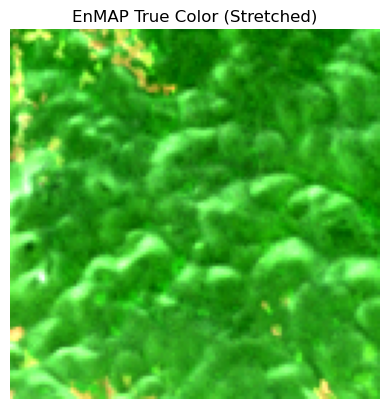

In [8]:
import matplotlib.pyplot as plt

def get_true_rgb(file_path):
    with rasterio.open(file_path) as src:
        # Load Red, Green, Blue
        rgb = src.read([45, 29, 15]).astype('float32')
        
        # Reshape from (3, 128, 128) to (128, 128, 3) for plotting
        rgb = np.moveaxis(rgb, 0, -1)
        
        # Apply a 2% Linear Stretch
        # This converts raw reflectance (0-5000+) to a 0-1 float range
        low = np.nanpercentile(rgb, 2)
        high = np.nanpercentile(rgb, 98)
        
        # Clip and Normalize
        rgb_stretched = np.clip((rgb - low) / (high - low), 0, 1)
        
        return rgb_stretched

# Depicting the result
rgb_image = get_true_rgb(file_path)
plt.imshow(rgb_image)
plt.title("EnMAP True Color (Stretched)")
plt.axis('off')
plt.show()

In [ ]:
import streamlit as st
import rasterio
from rasterio.warp import transform_bounds
import leafmap.foliumap as leafmap
import os
from texture_filters import occurrence_measures, cooccurrence_measures

# 1. Configure the page
st.set_page_config(page_title="Multi-Raster Viewer", layout="wide")
st.title("EnMAP Custom Composite Viewer")

# 2. Create the User Interface (UI) Elements
st.write("Enter the full paths to your .tif files below (one path per line):")
file_paths_str = st.text_area(
    label='File Paths:',
    value=r"C:\Users\shash\Downloads\projects\hstool\hybiomass_south_asia\hybiomass_dataset\South_Asia\01931\024.tif",
    height=100,
    placeholder="C:\\path\\to\\file1.tif\nC:\\path\\to\\file2.tif"
)

st.divider()

# Visualization Type Selector
vis_mode = st.selectbox(
    "Select Visualization Type",
    ["RGB Composite (Hyperspectral)", "Aboveground Biomass (AGBD)", "Plant Functional Type (PFT)"]
)

st.subheader("Visualization Settings")

# Initialize variables to hold dynamic settings
plot_bands = []
cmap = None
vmin_val = 0
vmax_val = 1

# Conditionally show UI based on selected mode
if vis_mode == "RGB Composite (Hyperspectral)":
    st.write("Select bands for RGB Composite (1-202):")
    col1, col2, col3 = st.columns(3)
    with col1:
        r_band = st.number_input('Red Band:', value=45, step=1, min_value=1, max_value=202)
    with col2:
        g_band = st.number_input('Green Band:', value=29, step=1, min_value=1, max_value=202)
    with col3:
        b_band = st.number_input('Blue Band:', value=15, step=1, min_value=1, max_value=202)
    
    col4, col5 = st.columns(2)
    with col4:
        vmin_val = st.number_input('Vmin (Reflectance):', value=110)
    with col5:
        vmax_val = st.number_input('Vmax (Reflectance):', value=2000)
        
    plot_bands = [int(r_band), int(g_band), int(b_band)]

elif vis_mode == "Aboveground Biomass (AGBD)":
    st.write("Visualizing Band 203 (AGBD)")
    col1, col2, col3 = st.columns(3)
    with col1:
        cmap = st.selectbox('Colormap:', ['viridis', 'Greens', 'YlGn', 'plasma'])
    with col2:
        # Biomass default max is usually lower than reflectance, adjust as needed based on your data scale
        vmin_val = st.number_input('Vmin (Biomass):', value=0.0) 
    with col3:
        vmax_val = st.number_input('Vmax (Biomass):', value=300.0)
        
    plot_bands = [203]

elif vis_mode == "Plant Functional Type (PFT)":
    st.write("Visualizing Band 204 (MODIS Type 5 PFT Scheme)")
    col1, col2, col3 = st.columns(3)
    with col1:
        # Categorical colormaps are best for classification data
        cmap = st.selectbox('Colormap:', ['tab20', 'Set1', 'Paired'])
    with col2:
        vmin_val = st.number_input('Vmin (Class Min):', value=0)
    with col3:
        vmax_val = st.number_input('Vmax (Class Max):', value=15)
        
    plot_bands = [204]

st.divider()

# 3. Helper function to calculate the combined Lat/Lon center
def get_combined_map_center(filepaths):
    min_left, min_bottom, max_right, max_top = float('inf'), float('inf'), float('-inf'), float('-inf')
    
    for filepath in filepaths:
        with rasterio.open(filepath) as src:
            bounds = src.bounds
            crs = src.crs
            # Transform the bounding box to EPSG:4326 (Lat/Lon)
            left, bottom, right, top = transform_bounds(crs, 'EPSG:4326', *bounds)
            
            # Update combined bounding box
            min_left = min(min_left, left)
            min_bottom = min(min_bottom, bottom)
            max_right = max(max_right, right)
            max_top = max(max_top, top)
            
    lat = (min_bottom + max_top) / 2
    lon = (min_left + max_right) / 2
    return lat, lon

# 4. The main logic triggered by the button
if st.button("Render Map", type="primary"):
    # Clean up the input string into a list of valid paths
    file_paths = [f.strip() for f in file_paths_str.split('\n') if f.strip()]
    
    if file_paths:
        with st.spinner(f"Rendering {vis_mode}... Please wait."):
            try:
                # Calculate the exact center based on all provided rasters
                lat, lon = get_combined_map_center(file_paths)
                
                # Initialize map
                m = leafmap.Map(center=[lat, lon], zoom=11)
                
                # Loop through each file and add it to the map
                for filepath in file_paths:
                    if not os.path.exists(filepath):
                        st.warning(f"File not found, skipping: {filepath}")
                        continue
                        
                    filename = os.path.basename(filepath)
                        # OPEN raster
                    with rasterio.open(filepath) as src:
                        data = src.read(1)

                        # APPLY FILTERS
                        if filter_type == "Texture":

                        if texture_type == "Occurrence Measures":
                            data = occurrence_measures(data, occ_measure)

                        elif texture_type == "Co-occurrence Measures":
                            data = cooccurrence_measures(data, co_measure)

                    
                    # Add raster with dynamic parameters based on mode
                    m.add_raster(
                        filepath, 
                        bands=plot_bands, 
                        cmap=cmap, # Will be ignored by leafmap if plotting 3 RGB bands
                        vmin=vmin_val, 
                        vmax=vmax_val,
                        layer_name=f"{filename} - {vis_mode.split(' ')[0]}"
                    )
                
                # Display it in Streamlit!
                m.to_streamlit(height=600)
                
            except Exception as e:
                st.error(f"Oops! Something went wrong while rendering: {e}")
    else:
        st.warning("Please provide at least one valid file path.")

st.subheader("Filters")

filter_type = st.selectbox(
    "Select Filter Type",
    ["None", "Texture", "Adaptive", "FFT Filtering"]
)

texture_type = None
occ_measure = None
co_measure = None

if filter_type == "Texture":

    texture_type = st.selectbox(
        "Texture Method",
        ["Occurrence Measures", "Co-occurrence Measures"]
    )

    if texture_type == "Occurrence Measures":
        occ_measure = st.selectbox(
            "Occurrence Measure",
            ["Mean", "Variance", "Std", "Entropy", "Energy"]
        )

    elif texture_type == "Co-occurrence Measures":
        co_measure = st.selectbox(
            "Co-occurrence Measure",
            ["Contrast", "Correlation", "Energy", "Homogeneity"]
        )

elif filter_type == "Adaptive":
    st.info("Adaptive filtering will be added here later.")

elif filter_type == "FFT Filtering":
    st.info("FFT filtering will be added here later.")